# Part 2 — final outcome model

**Final scored artifact: file 13, reported Kaggle log loss 0.58465 (lower is better).**
The exact CSV is `part2_best_submission.csv`. We predict success for phases I, II
and III, compare an eligibility-text baseline with our improved models, inspect
errors using Part 1 stopping reasons, and export the selected predictions.

Run all cells to independently rescore the saved held-out predictions, regenerate
figures, and replay the final blend. Set `RUN_FINAL_TRAINING=True` near the end
to **fit the actual model from raw supplied data**, with no old model caches.
Saved-probability replay and fresh training are identified separately.

[Experiment history](02_experiments.ipynb) · [Full implementation](03_source_code.ipynb)
· [Development narrative](resources/MODEL_DEVELOPMENT.md)
· [Original template](https://colab.research.google.com/drive/1mECHFXxHQnHAQiq5T3VPxeAjHXwFK7TG)

In [1]:
from pathlib import Path
import hashlib, json, os, runpy, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

locations = [candidate for base in [Path.cwd(), *Path.cwd().parents]
             for candidate in (base, base / "submission/midterm/part2", base / "midterm/part2")]
HANDIN = next(p for p in locations if (p / "01_final_model.ipynb").is_file())
ROOT = HANDIN / "resources"
assert (ROOT / "run.py").is_file(), "Run python part2/packaging/build_handin.py first, or extract the complete hand-in ZIP."
WORKSPACE = runpy.run_path(str(ROOT / "run.py"))["prepare_workspace"](ROOT)
sys.path.insert(0, str(WORKSPACE))
GENERATED = HANDIN / "generated"
GENERATED.mkdir(exist_ok=True)
sha256 = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
from experiments import load_data, metrics, PHASES
data = load_data()
SPRINT = ROOT / "experiments/leaderboard_sprint/runs/4dc0f274d45bce9e"
ledger = json.loads((ROOT / "submissions/leaderboard_results.json").read_text())
pd.set_option("display.max_rows", 16)
pd.set_option("display.max_columns", 12)


## Supplied data and evaluation boundaries

We have 8,037 training outcomes, 1,013 validation outcomes, and 1,500 unlabeled
test rows. Outcome label 1 means success. IDs are used for joins and splitting,
never as predictors. No additional dataset was downloaded and no deep learning
model was trained. Input data and the supplied pathway catalog are included.

The primary benchmark refits preprocessing inside each outer/inner training
split. It uses the official validation split, three forward windows, two
repeats of three-fold trial-grouped CV, and three longer-gap checks. The
grouped CV pool contains train + validation, with every evaluation trial
excluded from its fitting fold. The metric gives phases I, II and III equal weight.

The final fit uses all 9,050 labeled rows. As in Ani's published recipe, its
Ani-derived vocabulary/IDF fits use **unlabeled text from all three supplied
splits**, including test. The original text/tree component fits preprocessing
on labeled fitting rows. Test outcomes are never available. Strict benchmark
and published-preprocessing results are reported separately.

In [2]:
protocol = json.loads((ROOT / "experiments/local_benchmark/protocol.json").read_text())
for split, expected in protocol["data_sha256"].items():
    assert sha256(ROOT / "data" / f"outcome_{split}.csv") == expected
assert "label" not in data["test"]
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not set(data[a].trial_id) & set(data[b].trial_id)
display(pd.DataFrame([dict(split=k, rows=len(v), trials=v.trial_id.nunique(),
                           outcome_labels="label" in v) for k, v in data.items()]))
display(pd.DataFrame([{k: v for k, v in s.items() if k not in ["fit_ids", "eval_ids"]}
                      for s in protocol["splits"]]))


,split,rows,trials,outcome_labels
0,train,8037,7535,True
1,val,1013,901,True
2,test,1500,1442,False


,name,kind,repeat,fit_rows,eval_rows,eval_phase_counts,fit_year_max,eval_year_min,eval_year_max
0,official,official,NaN,8037,1013,"{'II': 501, 'III': 363, 'I': 149}",2013.0,1995.0,2013.0
1,time_2007_to_2008_2009,temporal,NaN,5319,1441,"{'II': 749, 'III': 477, 'I': 215}",2007.0,2008.0,2009.0
2,time_2009_to_2010_2011,temporal,NaN,6760,1805,"{'II': 866, 'III': 652, 'I': 287}",2009.0,2010.0,2011.0
3,time_2011_to_2012_2013,temporal,NaN,8565,485,"{'II': 223, 'III': 168, 'I': 94}",2011.0,2012.0,2013.0
4,group_repeat0_fold0,group_cv,0.0,6033,3017,"{'II': 1483, 'III': 1146, 'I': 388}",2013.0,1994.0,2013.0
5,group_repeat0_fold1,group_cv,0.0,6033,3017,"{'II': 1484, 'III': 1146, 'I': 387}",2013.0,1993.0,2013.0
6,group_repeat0_fold2,group_cv,0.0,6034,3016,"{'II': 1484, 'III': 1146, 'I': 386}",2013.0,1993.0,2013.0
7,group_repeat1_fold0,group_cv,1.0,6033,3017,"{'II': 1484, 'III': 1145, 'I': 388}",2013.0,1994.0,2013.0
8,group_repeat1_fold1,group_cv,1.0,6033,3017,"{'II': 1483, 'III': 1147, 'I': 387}",2013.0,1993.0,2013.0
9,group_repeat1_fold2,group_cv,1.0,6034,3016,"{'II': 1484, 'III': 1146, 'I': 386}",2013.0,1993.0,2013.0


## Frozen final recipe

`p13 = 0.70 * p10 + 0.30 * p01`, clipped to [0.001, 0.999].
File 10 is half Ani's recency stack and half our faster-recency stack with
eight neighbor features. The original ensemble `p01` combines a
three-logistic-regression mixture (50%) with CatBoost depth 6 and depth 8
(25% each). The final weights are frozen, not searched again here.

The Ani base learners use text TF-IDF, logistic regression, multinomial
Naive Bayes, and same-phase neighbors. Grouped out-of-fold predictions train
the logistic stacking layer. Eligibility, disease, drug and ICD text,
phase, and supplied drug knowledge support the components; stopping reasons
and Part 1 embeddings are excluded from outcome training.

The full fresh-fit orchestration appears below. Every model, preprocessing,
benchmark, and plot implementation is readable in the code appendix.

## Validation against the baseline and both Ani references

These predictions were generated with the 1,013 official validation rows
held out of supervised fitting. They are **not** predictions from the final
model fitted on train + validation. We recompute all metrics from saved row
probabilities. F1 uses a 0.5 success threshold; PR-AUC is average precision.

,model,phase,logloss,f1,roc_auc,pr_auc
0,Eligibility LR baseline,I,0.556186,0.765027,0.783456,0.834897
1,Eligibility LR baseline,II,0.599672,0.656716,0.740086,0.717348
2,Eligibility LR baseline,III,0.529385,0.833021,0.774187,0.862434
3,Ani unweighted,I,0.567686,0.752809,0.775184,0.820039
4,Ani unweighted,II,0.590758,0.668122,0.749984,0.732612
5,Ani unweighted,III,0.513665,0.821293,0.789634,0.883276
6,Ani recency,I,0.555754,0.792899,0.793750,0.829987
7,Ani recency,II,0.592863,0.646925,0.753486,0.732118
8,Ani recency,III,0.516499,0.824859,0.789804,0.881745
9,File 10,I,0.560222,0.761905,0.786949,0.824039


,phase_mean_logloss
Eligibility LR baseline,0.561748
Ani unweighted,0.557370
Ani recency,0.555039
File 10,0.557839
File 13 (final),0.553279


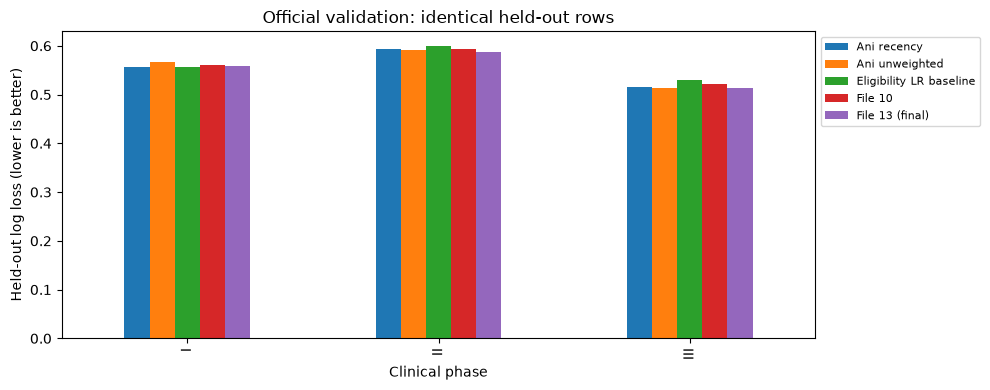

In [3]:
validation = data["val"]
predictions = {"Eligibility LR baseline": np.load(
    ROOT / "experiments/model_search/linear_validation_predictions.npz"
)["lr_criteria_none_C2_phase0"]}
names = {"Ani unweighted": "ani_first", "Ani recency": "ani_stack",
         "File 10": "file10", "File 13 (final)": "mix_legacy01_0.3"}
for label, name in names.items():
    saved = pd.read_csv(SPRINT / "strict/predictions/official" / f"{name}.csv")
    assert saved[["ID", "trial_id", "phase", "label"]].equals(
        validation[["ID", "trial_id", "phase", "label"]])
    predictions[label] = saved.probability.to_numpy()
scores = {name: metrics(validation, p) for name, p in predictions.items()}
assert abs(scores["File 13 (final)"]["phase_mean_logloss"] - 0.5532789641183768) < 1e-12
phase_table = pd.DataFrame([dict(model=name, phase=phase,
    **{metric: score[phase+"_"+metric] for metric in ["logloss", "f1", "roc_auc", "pr_auc"]})
    for name, score in scores.items() for phase in PHASES])
display(phase_table)
display(pd.DataFrame(scores).T[["phase_mean_logloss"]])
phase_table.to_csv(GENERATED / "validation_phase_metrics.csv", index=False)

ax = phase_table.pivot(index="phase", columns="model", values="logloss").plot.bar(figsize=(10, 4))
ax.set(ylabel="Held-out log loss (lower is better)", xlabel="Clinical phase",
       title="Official validation: identical held-out rows")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(GENERATED / "validation_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


## Post-hoc stopping-reason analysis

On known failed validation trials, a false-success error means predicted
probability ≥ 0.5. The supplied frozen reason table uses known Part 1 labels
where available and historical inferred labels elsewhere. Their counts are
shown separately; unmatched trials remain a separate category. Reasons can
overlap, and inferred reasons add uncertainty. This table is joined **after**
outcome prediction and does not affect any model score or fit.

This Part 2 package consumes the existing reason-label export and its provenance;
it does not train or revise Part 1. No Part 1 checkout is needed to reproduce
these tables and plots.

{'path': 'part1/experiments/additional_methods/classifier_models/dbscan_m5_q25__logistic_C1000.joblib',
 'sha256': '522ae60a545a600b9f993ce4fac66d55e37c8ae8c4d7ba1dbe7dfa72f82598a3',
 'policy': 'Visible Part 1 train/val labels when available; otherwise frozen DBSCAN/logistic Part 1 model, cutoff 0.5, argmax fallback.',
 'usage': 'Error analysis only; none of these columns or embeddings is an outcome predictor.'}

Phase I: baseline and final model; rates are among known failed trials


,reason,n,false_success,false_success_rate,wilson_lower,wilson_upper,true_reason_rows,predicted_reason_rows,model
0,Safety,9,5,0.555556,0.266647,0.811225,1,8,Eligibility LR baseline
1,Funding,4,2,0.500000,0.150036,0.849964,1,3,Eligibility LR baseline
2,Efficacy,2,1,0.500000,0.094529,0.905471,0,2,Eligibility LR baseline
3,Recruitment,22,8,0.363636,0.197330,0.570487,2,20,Eligibility LR baseline
4,Other,5,4,0.800000,0.375528,0.963777,0,5,Eligibility LR baseline
5,No recorded stopping reason,28,12,0.428571,0.265083,0.609295,0,0,Eligibility LR baseline
18,Safety,9,3,0.333333,0.120582,0.645803,1,8,File 13 (final)
19,Funding,4,1,0.250000,0.045586,0.699364,1,3,File 13 (final)
20,Efficacy,2,2,1.000000,0.342372,1.000000,0,2,File 13 (final)
21,Recruitment,22,2,0.090909,0.025295,0.278154,2,20,File 13 (final)


Phase II: baseline and final model; rates are among known failed trials


,reason,n,false_success,false_success_rate,wilson_lower,wilson_upper,true_reason_rows,predicted_reason_rows,model
6,Safety,15,6,0.400000,0.198242,0.642536,1,14,Eligibility LR baseline
7,Funding,4,0,0.000000,0.000000,0.489900,1,3,Eligibility LR baseline
8,Efficacy,10,3,0.300000,0.107789,0.603227,0,10,Eligibility LR baseline
9,Recruitment,87,17,0.195402,0.125733,0.290834,12,75,Eligibility LR baseline
10,Other,18,6,0.333333,0.162786,0.562509,3,15,Eligibility LR baseline
11,No recorded stopping reason,144,50,0.347222,0.274346,0.428039,0,0,Eligibility LR baseline
24,Safety,15,5,0.333333,0.151761,0.582869,1,14,File 13 (final)
25,Funding,4,0,0.000000,0.000000,0.489900,1,3,File 13 (final)
26,Efficacy,10,3,0.300000,0.107789,0.603227,0,10,File 13 (final)
27,Recruitment,87,12,0.137931,0.080697,0.225788,12,75,File 13 (final)


Phase III: baseline and final model; rates are among known failed trials


,reason,n,false_success,false_success_rate,wilson_lower,wilson_upper,true_reason_rows,predicted_reason_rows,model
12,Safety,6,3,0.500000,0.187613,0.812387,1,5,Eligibility LR baseline
13,Funding,0,0,NaN,NaN,NaN,0,0,Eligibility LR baseline
14,Efficacy,9,8,0.888889,0.564994,0.980110,0,9,Eligibility LR baseline
15,Recruitment,21,11,0.523810,0.323692,0.716563,5,16,Eligibility LR baseline
16,Other,8,5,0.625000,0.305738,0.863158,2,6,Eligibility LR baseline
17,No recorded stopping reason,82,46,0.560976,0.453227,0.663266,0,0,Eligibility LR baseline
30,Safety,6,3,0.500000,0.187613,0.812387,1,5,File 13 (final)
31,Funding,0,0,NaN,NaN,NaN,0,0,File 13 (final)
32,Efficacy,9,7,0.777778,0.452583,0.936776,0,9,File 13 (final)
33,Recruitment,21,12,0.571429,0.365462,0.755303,5,16,File 13 (final)


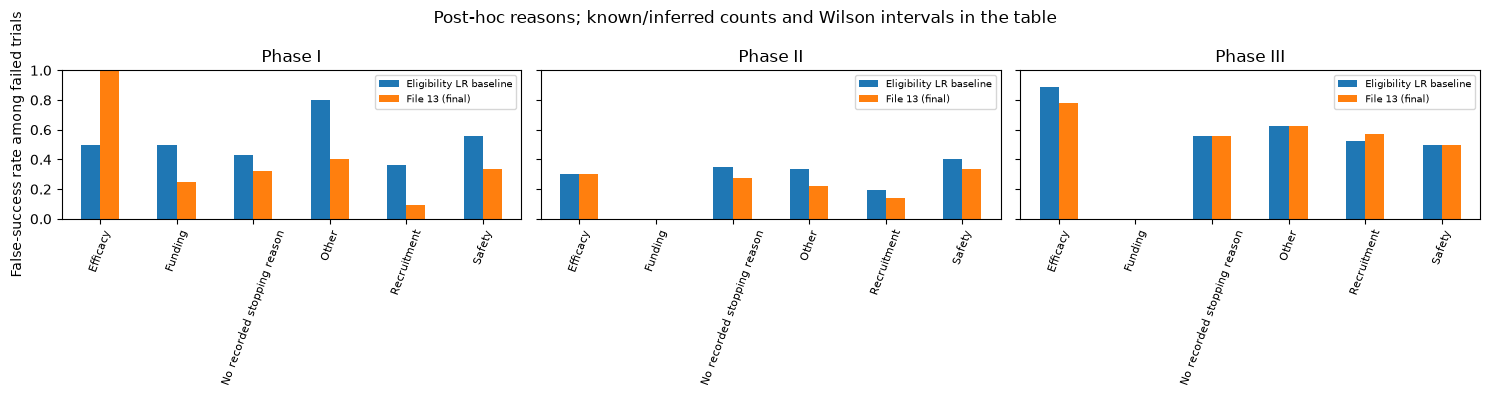

In [4]:
from error_analysis import errors_by_reason
reason_labels = pd.read_csv(ROOT / "experiments/model_search/reason_labels_for_analysis.csv")
display(json.loads((ROOT / "experiments/model_search/reason_model_provenance.json").read_text()))
reason_table = pd.concat([errors_by_reason(validation, predictions[name], reason_labels).assign(model=name)
    for name in ["Eligibility LR baseline", "File 13 (final)"]], ignore_index=True)
for phase in PHASES:
    print(f"Phase {phase}: baseline and final model; rates are among known failed trials")
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        display(reason_table.loc[reason_table.phase.eq(phase)].drop(columns="phase"))
reason_table.to_csv(GENERATED / "reason_errors.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for phase, ax in zip(PHASES, axes):
    subset = reason_table[reason_table.phase.eq(phase)]
    subset.pivot(index="reason", columns="model", values="false_success_rate").plot.bar(ax=ax)
    ax.set(title=f"Phase {phase}", xlabel="", ylim=(0, 1))
    ax.tick_params(axis="x", labelrotation=70, labelsize=8)
    ax.legend(fontsize=7)
axes[0].set_ylabel("False-success rate among failed trials")
fig.suptitle("Post-hoc reasons; known/inferred counts and Wilson intervals in the table")
fig.tight_layout()
fig.savefig(GENERATED / "reason_errors.png", dpi=160, bbox_inches="tight")
plt.show()


## From the baseline to the improved classifier

The eligibility-only logistic baseline misses failures in several stopping-reason groups. We broadened the outcome features with disease, drug and ICD text, added same-phase neighbor signals and recency weighting, and combined complementary text/tree and stacking models. Notebook [02](02_experiments.ipynb) records that development sequence and its unsuccessful alternatives. The reason comparison here is retrospective: we use it to assess the changes, without treating a small reason subgroup as an independent tuning set or feeding its labels into outcome training.

On official validation, equal-phase log loss improves from **0.56175** to **0.55328**. At the fixed 0.5 threshold, F1 changes from **0.7650 → 0.7882** in phase I, **0.6567 → 0.6469** in phase II, and **0.8330 → 0.8390** in phase III. ROC-AUC improves in all three phases; PR-AUC improves in phases II and III and falls slightly in phase I. Better probability loss therefore does not imply better F1 at every phase's fixed threshold.

Recruitment false-success rates fall from **8/22 → 2/22** in phase I and **17/87 → 12/87** in phase II, but rise from **11/21 → 12/21** in phase III. The no-recorded-reason group improves from **12/28 → 9/28** and **50/144 → 40/144** in phases I and II, while phase III stays **46/82**. Phase I Efficacy worsens from **1/2 → 2/2**; its two inferred-label trials cannot support a broad conclusion. Phase III Funding has no examples, so its rate is undefined. Most matched reason labels are inferred, categories overlap, and the intervals are wide for rare groups. These limits matter when interpreting apparent gains.


## Exact scored artifact and recorded-component replay

The small component archive contains native predictions from the original
fitted models, with their cache hashes recorded. Recombining these arrays
checks the final recipe and CSV; **it is not a new fit**. We preserve the
exact scored CSV bytes separately from newly serialized predictions.

In [5]:
artifact = ROOT / "submissions/13_file10_legacy30.csv"
expected_sha = "be29fc849f63ed4c23b31e67c97aaa97c6940f569b0af0920cf9799b428f7636"
assert sha256(artifact) == sha256(HANDIN / "part2_best_submission.csv") == expected_sha
provenance = json.loads((ROOT / "experiments/final_handin/recorded_components_provenance.json").read_text())
component_path = ROOT / "experiments/final_handin/recorded_components.npz"
assert sha256(component_path) == provenance["component_archive_sha256"]
with np.load(component_path) as components:
    assert components["ID"].tolist() == data["test"].ID.tolist()
    file10 = .5*components["ani_stack"] + .5*components["fast2_neighbors"]
    replay = np.clip(.7*file10 + .3*components["legacy01"], .001, .999)
recorded = pd.read_csv(artifact)
sample = pd.read_csv(ROOT / "data/part2_sample_submission.csv")
assert recorded.ID.equals(sample.ID) and recorded.ID.is_unique and len(recorded) == 1500
replay_error = float(np.max(np.abs(recorded.label - replay)))
assert replay_error < 1e-12
pd.DataFrame(dict(ID=data["test"].ID, label=replay)).to_csv(GENERATED / "recorded_blend_replay.csv", index=False)
(GENERATED / "exact_scored_submission.csv").write_bytes(artifact.read_bytes())
display(dict(kaggle_score=ledger["current_best"]["kaggle_score"],
             exact_csv_sha256=expected_sha, recorded_component_replay_max_error=replay_error))


{'kaggle_score': 0.58465,
 'exact_csv_sha256': 'be29fc849f63ed4c23b31e67c97aaa97c6940f569b0af0920cf9799b428f7636',
 'recorded_component_replay_max_error': 1.1102230246251565e-16}

## Fresh final training from raw data

This code calls the preserved model implementations, refits both stacking
banks and the original text/tree ensemble, checks disjoint stacking folds,
and tests native inference after replacing IDs and adding a dummy label.
It writes to `generated/fresh_fit/`, leaving the scored artifact intact.
Set the flag in the following cell to run it. This takes substantially longer
than replaying saved probabilities. Machine/library differences may change
floating-point results; the receipt records versions and numerical differences.

In [6]:
"""Refit file 13 from the supplied CSVs without reading existing fitted caches.

The same implementation is embedded in the finalized model notebook. Run with
Python 3.12 and part2/requirements/requirements-all-submissions.txt installed.
"""
from pathlib import Path
import argparse
import hashlib
import importlib.metadata
import json
import os
import runpy
import sys
import time

for _key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
             "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_key, "2")


def refit_final(part2_root, output_dir):
    """Train the frozen recipe, replay it on feature-only rows, and save a new CSV."""
    root, output = Path(part2_root).resolve(), Path(output_dir).resolve()
    output.mkdir(parents=True, exist_ok=True)
    workspace = runpy.run_path(str(root / "run.py"))["prepare_workspace"](root)
    sys.path.insert(0, str(workspace))
    import numpy as np
    import pandas as pd
    from threadpoolctl import threadpool_limits
    from ani_models import AniFeatures
    from experiments import load_data
    from improvement_models import fit_bank, fit_recipes as fit_base_metas
    from extension_neighbors import fit_extended, fit_recipes as fit_neighbor_metas
    from all_submission_models import LegacySubmissions
    from sprint_export import native_packets, original_components

    started = time.monotonic()
    def progress(message):
        print(f"{time.monotonic() - started:.1f}s: {message}", flush=True)

    data = load_data()
    train = pd.concat([data["train"], data["val"]], ignore_index=True)
    test = data["test"]
    assert len(train) == 9050 and len(test) == 1500
    assert not set(train.trial_id) & set(test.trial_id)
    assert "label" not in test
    # Frozen published-recipe preprocessing: vocabulary/IDF see all supplied
    # texts; supervised fits and grouped stacking folds use labeled rows only.
    with threadpool_limits(limits=2):
        features = AniFeatures().fit(pd.concat(list(data.values()), ignore_index=True))
        progress("fitted vocabulary/IDF on supplied train, validation, and test text")
        old = fit_bank(train, test, features=features, retain_models=True,
                       progress=lambda message: progress("base bank " + message))
        baseline, base_metas = fit_base_metas(old, train, test)
        extra = fit_extended(train, test, old, space=features, retain=True,
                             progress=lambda fold: progress(f"neighbor bank inner {fold}/5"))
        neighbors, neighbor_metas = fit_neighbor_metas(old, extra, train, test, baseline)
        legacy = LegacySubmissions().fit(train, progress=progress)
        legacy_probability = legacy.predict(test)["01_balanced_ensemble"]
        probability = np.clip(.7 * neighbors["fast2_neighbors_half"]
                              + .3 * legacy_probability, .001, .999)

        # Replay actual fitted models after removing outcomes and replacing IDs.
        query = test.copy()
        query["ID"] = "unused"
        query["trial_id"] = "unused"
        query["label"] = 0
        bundle = dict(old=old, extra=extra, base_metas=base_metas,
                      neighbor_metas=neighbor_metas)
        replay_old, replay_extra = native_packets(bundle, query)
        components = original_components(bundle, replay_old, replay_extra, query)
        replay = np.clip(.7 * components["file10"]
                         + .3 * legacy.predict(query)["01_balanced_ensemble"], .001, .999)
    replay_error = float(np.max(np.abs(probability - replay)))
    assert replay_error < 1e-12, replay_error
    assert old["training_ids"] == extra["train_ids"] == legacy.training_ids == train.ID.tolist()
    for packet in (old, extra):
        for fold in packet["audit"]:
            heldout = fold.get("heldout_ids", fold.get("eval_ids"))
            assert not set(fold["fit_ids"]) & set(heldout)
            indexed = train.set_index("ID")
            assert not (set(indexed.loc[fold["fit_ids"], "trial_id"])
                        & set(indexed.loc[heldout, "trial_id"]))

    sample = pd.read_csv(root / "data/part2_sample_submission.csv")
    frame = pd.DataFrame(dict(ID=test.ID, label=probability)).set_index("ID").loc[sample.ID].reset_index()
    assert frame.ID.is_unique and frame.ID.equals(sample.ID)
    assert np.isfinite(frame.label).all() and frame.label.between(0, 1, inclusive="neither").all()
    destination = output / "13_file10_legacy30_refit.csv"
    frame.to_csv(destination, index=False)
    recorded = pd.read_csv(root / "submissions/13_file10_legacy30.csv")
    assert frame.ID.equals(recorded.ID)
    error = float(np.max(np.abs(frame.label - recorded.label)))
    sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
    receipt = dict(
        recipe={"file10": .7, "legacy01": .3}, training_rows=len(train),
        test_rows=len(test), existing_model_caches_read=False,
        native_replay_max_error=replay_error, recorded_csv_max_error=error,
        numerically_matches_recorded_at_1e_7=error < 1e-7,
        recorded_csv_sha256=sha(root / "submissions/13_file10_legacy30.csv"),
        refit_csv_sha256=sha(destination), elapsed_seconds=time.monotonic()-started,
        versions={p: importlib.metadata.version(p) for p in
                  ["numpy", "pandas", "scipy", "scikit-learn", "catboost", "joblib"]},
        data_sha256={p.name: sha(p) for p in sorted((root / "data").glob("*.csv"))},
        source_sha256={p.name: sha(p) for p in sorted((root / "src").glob("*.py"))},
        note="The Kaggle score belongs to the original CSV. A refit does not acquire that score.")
    (output / "refit_verification.json").write_text(json.dumps(receipt, indent=2) + "\n")
    progress(f"saved refit; maximum difference from scored CSV: {error:.3g}")
    return receipt


In [7]:
RUN_FINAL_TRAINING = False
if RUN_FINAL_TRAINING:
    fresh_receipt = refit_final(ROOT, GENERATED / "fresh_fit")
    display(fresh_receipt)
else:
    print("Fresh training is off. The checks above rescore held-out predictions and replay recorded components.")
verified_refit = ROOT / "experiments/final_handin/refit_verification.json"
if verified_refit.exists():
    print("Recorded verification of the fresh-fit path during hand-in preparation:")
    display(json.loads(verified_refit.read_text()))


Fresh training is off. The checks above rescore held-out predictions and replay recorded components.
Recorded verification of the fresh-fit path during hand-in preparation:


{'recipe': {'file10': 0.7, 'legacy01': 0.3},
 'training_rows': 9050,
 'test_rows': 1500,
 'existing_model_caches_read': False,
 'native_replay_max_error': 0.0,
 'recorded_csv_max_error': 1.1102230246251565e-16,
 'numerically_matches_recorded_at_1e_7': True,
 'recorded_csv_sha256': 'be29fc849f63ed4c23b31e67c97aaa97c6940f569b0af0920cf9799b428f7636',
 'refit_csv_sha256': 'be29fc849f63ed4c23b31e67c97aaa97c6940f569b0af0920cf9799b428f7636',
 'elapsed_seconds': 354.3945262087509,
 'versions': {'numpy': '2.5.2',
  'pandas': '3.0.5',
  'scipy': '1.18.1',
  'scikit-learn': '1.9.0',
  'catboost': '1.2.10',
  'joblib': '1.6.0'},
 'data_sha256': {'outcome_test.csv': '39fef81bb60e084e75f4cc0947c31e8400dace18fe9b6a0ea0e266240b9f679f',
  'outcome_train.csv': '7dabba85cc71515741efdb3a75ff7f1e87deb93b8fac410033ed962a6a314719',
  'outcome_val.csv': 'a49da3fbb168a18b776346c84f3b2d0bd137f6282935a260f811e47329d80a1b',
  'part2_sample_submission.csv': '15c38fd743cdaac694f0e9fff34f0060c97b11cf682cd22bd3434ad2

## Interpretation and limits

File 13 improved the reported Kaggle log loss from Ani's 0.58688 to 0.58465.
File 15 improved some local averages but scored 0.58492, so we retained file 13.
The final reserve was not submitted. Local validation was repeatedly used for
selection; bootstrap intervals do not correct for this adaptive search.
The reported rank and scores are historical team records and commit messages, not a live
leaderboard query. See the experiment notebook for all phases, failures,
controls, and the distinction between configurations and independent fits.

The recorded test log loss **0.58465** is worse than the strict official-validation estimate **0.55328** by about **0.03137**. The later test years make distribution shift a plausible contributor, alongside repeated model selection and the final recipe's different preprocessing policy. This comparison cannot separate those effects or reveal phase-specific test errors, since test labels are unavailable.